In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import plot_tree

In [6]:
from google.colab import files
uploaded = files.upload()

Saving household_electricity_data.csv to household_electricity_data.csv


In [7]:
df = pd.read_csv("household_electricity_data.csv")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1500, 7)
   number_of_occupants  temperature_c  appliance_usage_hours  \
0                    5          26.76                   6.38   
1                    3          28.94                   4.36   
2                    6          30.54                   4.72   
3                    5          33.63                   4.63   
4                    2          36.49                   7.75   

   previous_consumption_kwh  peak_hour_usage  household_size  \
0                     13.22             2.80               5   
1                     10.58             1.93               3   
2                     12.66             1.38               5   
3                     14.33             1.07               4   
4                     11.69             0.52               2   

   electricity_consumption_kwh  
0                        12.99  
1                        11.28  
2                        12.83  
3                        12.82  
4                        11.38  


In [8]:
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   number_of_occupants          1500 non-null   int64  
 1   temperature_c                1500 non-null   float64
 2   appliance_usage_hours        1500 non-null   float64
 3   previous_consumption_kwh     1500 non-null   float64
 4   peak_hour_usage              1500 non-null   float64
 5   household_size               1500 non-null   int64  
 6   electricity_consumption_kwh  1500 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 82.2 KB
None

Missing Values:
number_of_occupants            0
temperature_c                  0
appliance_usage_hours          0
previous_consumption_kwh       0
peak_hour_usage                0
household_size                 0
electricity_consumption_kwh    0
dtype: int64


In [9]:
X = df[[
    "number_of_occupants",
    "temperature_c",
    "appliance_usage_hours",
    "previous_consumption_kwh",
    "peak_hour_usage",
    "household_size"
]]

y = df["electricity_consumption_kwh"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (1200, 6)
Testing Data: (300, 6)


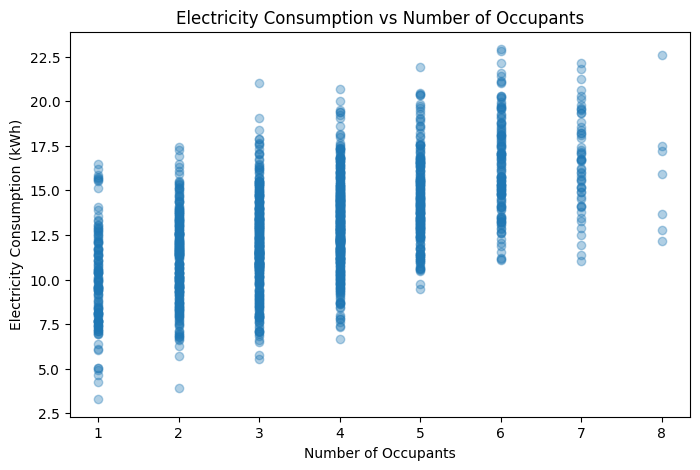

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["number_of_occupants"],
    df["electricity_consumption_kwh"],
    alpha=0.35
)
plt.xlabel("Number of Occupants")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Electricity Consumption vs Number of Occupants")
plt.show()

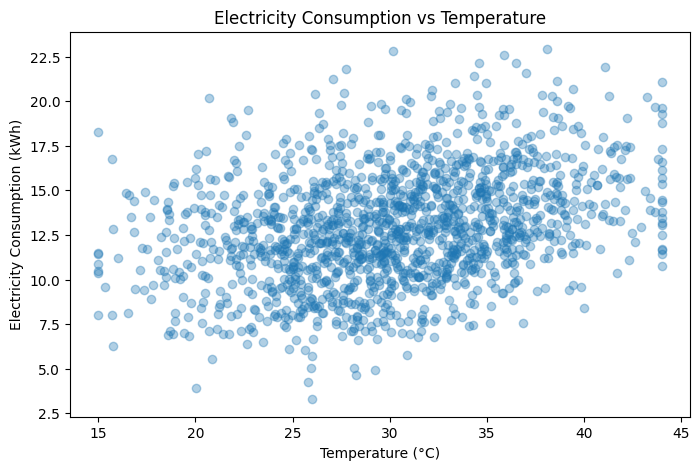

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["temperature_c"],
    df["electricity_consumption_kwh"],
    alpha=0.35
)
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Electricity Consumption vs Temperature")
plt.show()

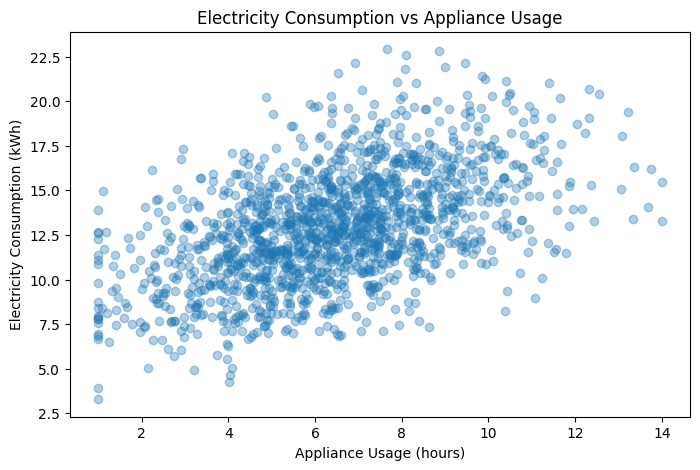

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["appliance_usage_hours"],
    df["electricity_consumption_kwh"],
    alpha=0.35
)
plt.xlabel("Appliance Usage (hours)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Electricity Consumption vs Appliance Usage")
plt.show()

In [13]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X_train, y_train)
print("Model Training Completed!")

Model Training Completed!


In [14]:
y_pred = model.predict(X_test)
print("Predicted Electricity Consumption (kWh):")
print(y_pred[:10])

Predicted Electricity Consumption (kWh):
[12.86967173 11.5576749   9.01888518 15.99077232 14.43476167 11.77444889
 16.96656155  7.97928232 15.5183752  12.56434028]


In [15]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2 :", r2)

MAE : 0.8676405819624818
RMSE: 1.0622152183471698
R2 : 0.8888202556110105


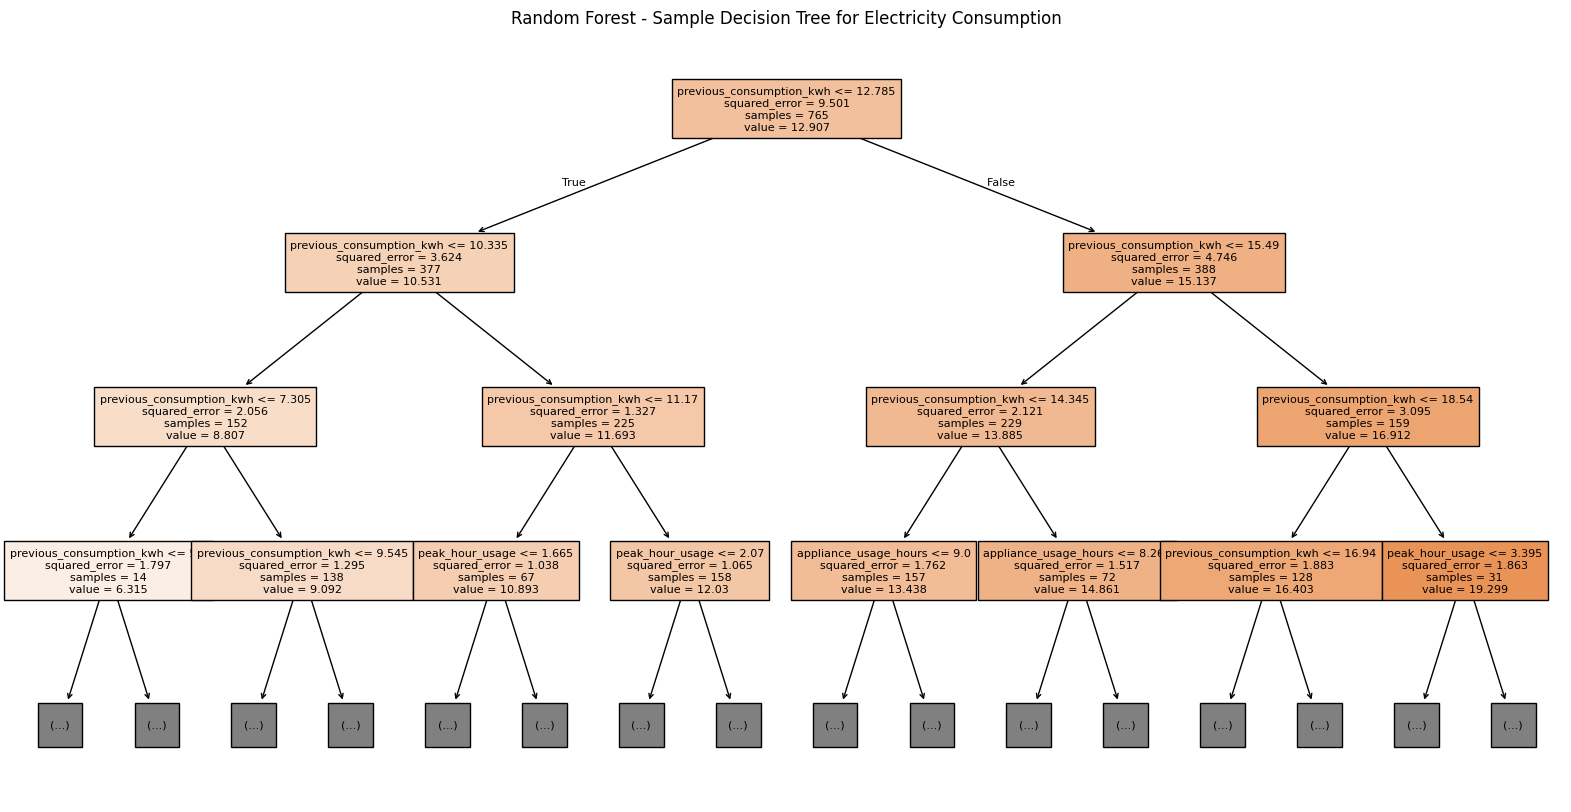

In [16]:
plt.figure(figsize=(20, 10))
plot_tree(
    model.estimators_[0],
    feature_names=X.columns,
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Random Forest - Sample Decision Tree for Electricity Consumption")
plt.savefig(
    "random_forest_electricity_tree.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
sample = pd.DataFrame([
    {
        "number_of_occupants": 4,
        "temperature_c": 32,
        "appliance_usage_hours": 8,
        "previous_consumption_kwh": 7.5,
        "peak_hour_usage": 3,
        "household_size": 4
    }
])

prediction = model.predict(sample)[0]
prediction = np.clip(prediction, 0, None)

print(
    "Predicted Electricity Consumption:",
    round(prediction, 2),
    "kWh"
)

Predicted Electricity Consumption: 8.78 kWh


In [18]:
if prediction < 10:
    print("Consumption Level: LOW")
elif prediction < 15:
    print("Consumption Level: MODERATE")
else:
    print("Consumption Level: HIGH")

Consumption Level: LOW
